# Alabama — Explain pretrained GridSFM feasibility predictions using Captum

**Notebook 2 of 2.** Reads scenarios from `01_alabama_gaussian_sampling_julia_acopf.ipynb` and explains how perturbing individual **Pd** and **Qd** loads changes the **pretrained GridSFM-Open v1.1** feasibility prediction.

- **No Julia initialization or AC-OPF solves here.** Julia solver labels are loaded solely for comparison.
- **No new classifier training.** This notebook does not need `alabama_surrogate_weights.pt` or `alabama_surrogate_scaler.npz`.
- **Reference (baseline):** original Alabama loads with identical topology and other features.
- **Explanations:** Captum Kernel SHAP for grouped load changes, followed by individual-load Feature Ablation. The second method is **not SHAP**.
- **Output:** figures (PNG and SVG), group and per-load CSV tables, and a JSON summary in `samples/gaussian_load_centered/pretrained_gridsfm_captum/`.

**Interpretation:** Attributions explain what changes **GridSFM's prediction**, not proven physical causes of AC-OPF infeasibility. Julia's result is an external comparison. Alabama has 494 buses, just below the checkpoint's documented 500-bus guidance, so validate predictions carefully.

Run cells top-to-bottom. Edit the paths and `SCENARIO_INDEX` as necessary.

In [7]:
# from pathlib import Path

# print("Current directory:", Path.cwd())

# root = Path.cwd()
# matches = list(root.rglob("alabama_model.pyg.json"))

# for parent in list(root.parents)[:3]:
#     matches.extend(parent.glob(
#         "**/alabama_model.pyg.json"
#     ))

# matches = sorted(set(p.resolve() for p in matches))

# if matches:
#     for path in matches:
#         print("Found:", path)
# else:
#     print("No Alabama PyG graph found.")

In [8]:
import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Match these paths to Notebook 1 and your GridSFM installation.
DATA_PATH = Path("../power_grid/US/gridsfm_data/16h/alabama_model.json")
OUTPUT_DIR = Path("samples/gaussian_load_centered")
SCENARIO_PATH = OUTPUT_DIR / "alabama_acopf_labeled_scenarios.npz"
EXPLAIN_DIR = OUTPUT_DIR / "pretrained_gridsfm_captum"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Alabama raw network not found: {DATA_PATH.resolve()}"
assert SCENARIO_PATH.is_file(), (f"Saved scenarios not found: {SCENARIO_PATH.resolve()}. "
                                 "Run Notebook 1 first, and confirm OUTPUT_DIR is the same.")
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
load_ids = [str(k) for k,v in data["load"].items() if int(v.get("status",1)) == 1]
loads = np.asarray([[float(data["load"][lid]["pd"]), float(data["load"][lid]["qd"])]
                    for lid in load_ids], dtype=float)
n_loads = len(load_ids)
print("Alabama:", DATA_PATH.resolve(), "| active loads:", n_loads)
print("Saved verification scenarios:", SCENARIO_PATH.resolve())

Alabama: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json | active loads: 494
Saved verification scenarios: /Users/punrong_rany/Desktop/Projects/GridSFM/model/samples/gaussian_load_centered/alabama_acopf_labeled_scenarios.npz


In [9]:
# Run once in your local Python/Jupyter environment if needed:
# %pip install captum
# In the GridSFM/model directory: %pip install -e .

import torch
from captum.attr import KernelShap, FeatureAblation
from gridsfm import load_model, load_pyg_json, prepare_for_inference, predict

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

CHECKPOINT_CANDIDATES = [
    Path("checkpoints/gridsfm_open_v1.1.pt"),
]
PYG_CANDIDATES = [
    Path("../power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json"),
]

def first_existing(paths, label):
    result = next((p.resolve() for p in paths if p.is_file()), None)
    if result is None:
        raise FileNotFoundError(f"Cannot locate {label}. Checked: {[str(p) for p in paths]}")
    return result

CHECKPOINT_PATH = first_existing(CHECKPOINT_CANDIDATES, "GridSFM checkpoint")
PYG_PATH = first_existing(PYG_CANDIDATES, "Alabama PyG graph")

print("Device:", DEVICE)
print("Checkpoint:", CHECKPOINT_PATH)
print("Alabama PyG graph:", PYG_PATH)

grid_model = load_model(str(CHECKPOINT_PATH), device=str(DEVICE))
grid_model.eval()
for parameter in grid_model.parameters():
    parameter.requires_grad_(False)
print("Pretrained GridSFM-Open loaded (NO surrogate training).")

Device: cpu
Checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt
Alabama PyG graph: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json
Pretrained GridSFM-Open loaded (NO surrogate training).


## 2 Verify exact load-ID mapping before explaining anything

The Julia notebook preserves original raw-JSON dictionary order; `.pyg.json` uses a different row order. We **must not** silently assume these orders match. For Alabama, the source graph's load rows must align with numerically sorted raw load IDs. This cell compares all baseline Pd and Qd values, and stops if there is any mismatch. This check does not rely on unique Pd/Qd values.

In [10]:
raw_graph = load_pyg_json(PYG_PATH)  # UNPREPARED graph
with PYG_PATH.open("r", encoding="utf-8") as f:
    pyg_metadata = json.load(f).get("metadata", {})

# Alabama source uses one active raw load for each graph load row, sorted by numeric load ID.
# Never assume that Python dictionary insertion order matches PyG order.
pyg_load_ids = sorted(load_ids, key=lambda s: int(s))
assert len(pyg_load_ids) == int(raw_graph["load"].x.shape[0]), (
    "Different load counts: cannot safely map raw load IDs to PyG rows."
)
raw_load_by_id = {lid: loads[j] for j, lid in enumerate(load_ids)}
pyg_original_loads = np.asarray([raw_load_by_id[lid] for lid in pyg_load_ids], dtype=np.float32)
np.testing.assert_allclose(
    pyg_original_loads,
    raw_graph["load"].x[:, :2].numpy(),
    rtol=1e-5, atol=2e-6,
    err_msg="The raw-to-PyG load ordering or baseline does NOT match. Stop here and inspect mapping."
)
pyg_to_notebook_index = np.asarray([load_ids.index(lid) for lid in pyg_load_ids], dtype=int)
assert np.unique(pyg_to_notebook_index).size == n_loads
assert len(loads) == int(raw_graph["load"].x.shape[0])

# Map each PyG load -> PyG bus -> physical bus identifier, then longitude.
bus_id_map = pyg_metadata.get("bus_id_map")
assert bus_id_map is not None and len(bus_id_map) == int(raw_graph["bus"].x.shape[0]), (
    "PyG metadata.bus_id_map missing: cannot accurately label load buses."
)
l2b = raw_graph[("load", "load_link", "bus")].edge_index.numpy()
assert len(l2b[0]) == n_loads
pyg_load_bus_idx = np.full(n_loads, -1, dtype=int)
pyg_load_bus_idx[l2b[0]] = l2b[1]
assert np.all(pyg_load_bus_idx >= 0)
pyg_load_bus_id = [str(bus_id_map[j]) for j in pyg_load_bus_idx]
for row, (lid, busid) in enumerate(zip(pyg_load_ids, pyg_load_bus_id)):
    assert int(data["load"][lid]["load_bus"]) == int(busid), (
        f"Load {lid} bus mismatch: raw={data['load'][lid]['load_bus']}, PyG={busid}"
    )
longitudes = np.array([float(data["bus"][busid]["lon"]) for busid in pyg_load_bus_id])
assert np.isfinite(longitudes).all()

print("MATCH: all", n_loads, "Alabama load rows and bus references align with PyG.")
print("Example PyG row 0: load ID", pyg_load_ids[0], "bus", pyg_load_bus_id[0])

MATCH: all 494 Alabama load rows and bus references align with PyG.
Example PyG row 0: load ID 1 bus 9


## 3 Load a saved Gaussian scenario and select one to explain

This step uses your actual saved Gaussian perturbations. **You do not need both classes (accepted and rejected)** because no new binary classifier is trained. Prefer an already Julia-verified scenario to compare the pretrained model with the solver.

In [11]:
SCENARIO_PATH = OUTPUT_DIR / "alabama_acopf_labeled_scenarios.npz"
assert SCENARIO_PATH.is_file(), "Run Gaussian sampling first, or set SCENARIO_PATH to your saved NPZ."
with np.load(SCENARIO_PATH, allow_pickle=False) as saved:
    candidates = saved["candidates"].astype(np.float32)
    julia_accepted = saved["accepted"].astype(int)
    saved_ids = saved["load_ids"].astype(str)
    saved_status = saved["status"].astype(str)
    saved_iteration = saved["iteration"].astype(int)
    saved_scenario = saved["scenario"].astype(int)
assert np.array_equal(saved_ids, np.array(load_ids, dtype=str)), "Saved candidates use different load order."
assert candidates.ndim == 3 and candidates.shape[1:] == loads.shape

# Change this to another 0-based row to explain a different scenario.
SCENARIO_INDEX = 0
assert 0 <= SCENARIO_INDEX < len(candidates)
chosen = candidates[SCENARIO_INDEX][pyg_to_notebook_index]  # PyG row order
original = pyg_original_loads.copy()
delta = chosen - original

print("Saved Julia-verified scenarios:", len(candidates))
print("Selected iteration/scenario:", saved_iteration[SCENARIO_INDEX], saved_scenario[SCENARIO_INDEX])
print("Julia solver:", saved_status[SCENARIO_INDEX], "accepted:", bool(julia_accepted[SCENARIO_INDEX]))
print("Original total Pd/Qd:", original.sum(axis=0))
print("Selected total Pd/Qd:", chosen.sum(axis=0))
print("Per-load mean |delta Pd/Qd|:", np.abs(delta).mean(axis=0))

Saved Julia-verified scenarios: 100
Selected iteration/scenario: 1 1
Julia solver: OPF_SOLVED accepted: True
Original total Pd/Qd: [95.011665 40.474792]
Selected total Pd/Qd: [99.23851 42.27519]
Per-load mean |delta Pd/Qd|: [0.05840066 0.02487745]


## Visual A — What actually changed in the loads?

These plots show the changes the pretrained model will be asked to explain. Pd and Qd are in the raw data's units (per-unit in your existing workflow). A scenario can have nearly unchanged total demand but large opposing changes at individual buses.

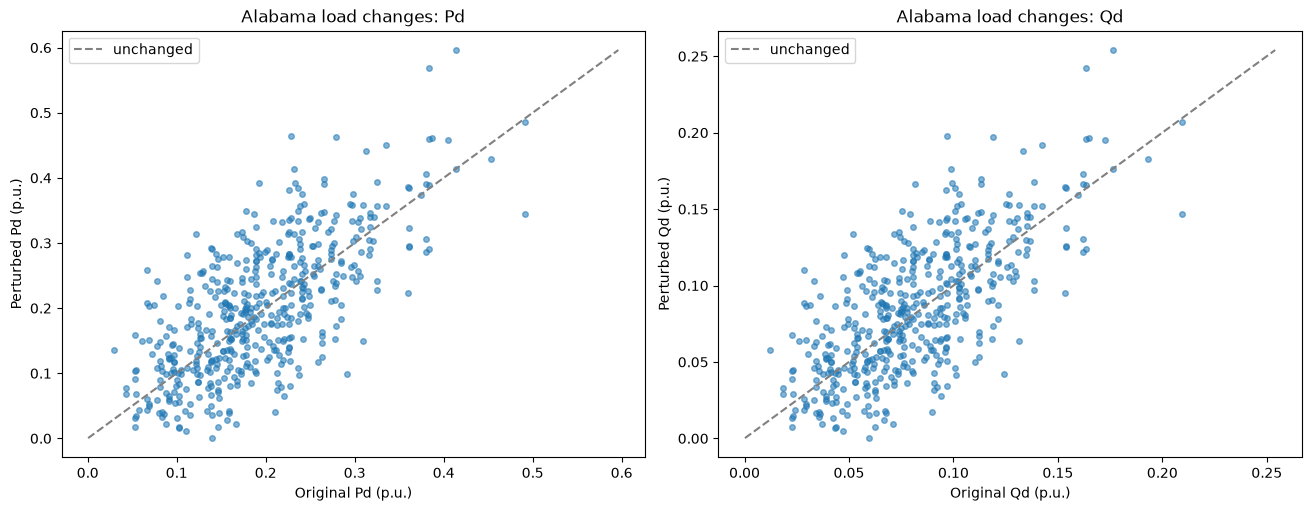

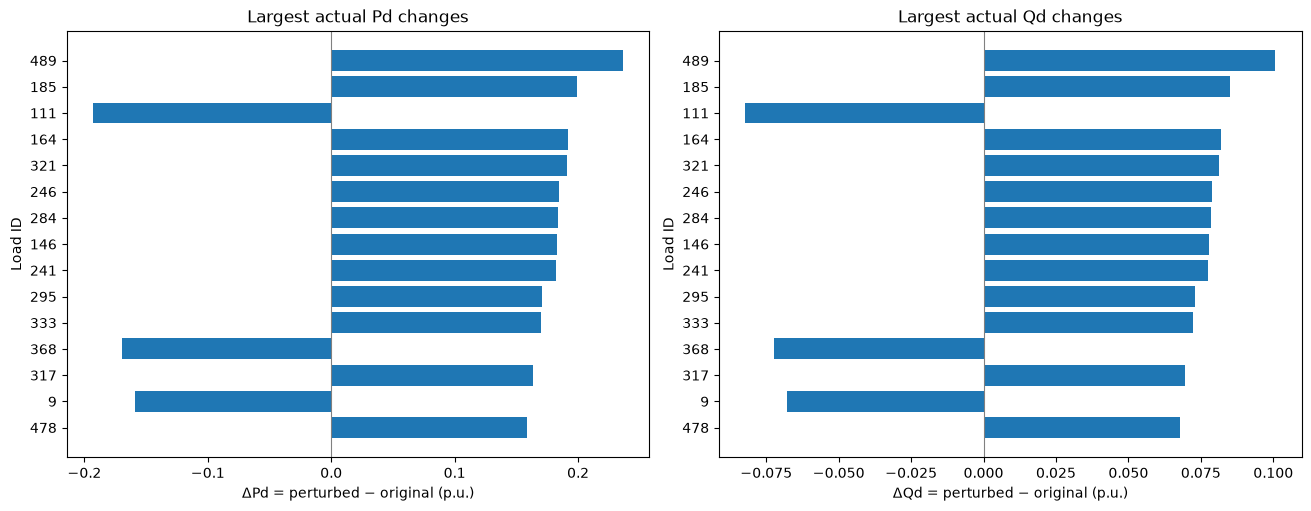

In [12]:
# Plot original vs perturbed values separately for Pd and Qd.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    axs[j].scatter(original[:, j], chosen[:, j], s=16, alpha=0.55)
    low = float(min(original[:, j].min(), chosen[:, j].min()))
    high = float(max(original[:, j].max(), chosen[:, j].max()))
    axs[j].plot([low, high], [low, high], ls="--", color="gray", label="unchanged")
    axs[j].set(xlabel=f"Original {name} (p.u.)", ylabel=f"Perturbed {name} (p.u.)",
               title=f"Alabama load changes: {name}")
    axs[j].legend(loc="best")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.svg", bbox_inches="tight")
plt.show()

# Most-changed loads, by absolute value within each channel (not model importance).
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    take = np.argsort(np.abs(delta[:, j]))[-15:][::-1]
    d = delta[take, j][::-1]
    axs[j].barh([str(pyg_load_ids[r]) for r in take[::-1]], d)
    axs[j].axvline(0, color="gray", lw=.8)
    axs[j].set(xlabel=f"Δ{name} = perturbed − original (p.u.)",
               ylabel="Load ID", title=f"Largest actual {name} changes")
fig.savefig(EXPLAIN_DIR / "00_top_load_changes.png", dpi=180, bbox_inches="tight")
plt.show()

## 4 GridSFM forward function: always recalculate load-dependent graph features

**Crucial:** GridSFM preprocessing computes DC-based node features and `g_ctx` from the current loads. Reusing a prepared base graph while modifying just `load.x` would create internally inconsistent model inputs. This wrapper clones the **raw** graph, replaces each load's Pd/Qd, then runs `prepare_for_inference` again for every Captum perturbation. This preserves the exact released checkpoint's inference pipeline. It is slower but scientifically more defensible.

The scalar being explained is the **pretrained model's probability of AC-OPF feasibility**, not the solver objective and not Julia's verdict.

In [13]:
# For reproducible inference, run single graphs; Captum's perturbations_per_eval=1 below.
def grid_probability_pygrid(pyg_load_array):
    vals = np.asarray(pyg_load_array, dtype=np.float32)
    if vals.shape != original.shape or not np.isfinite(vals).all():
        raise ValueError(f"Invalid load input {vals.shape}, expected {original.shape}.")
    # Original raw graph: topology and non-load features never change.
    g = raw_graph.clone()
    g["load"].x[:, :2] = torch.from_numpy(vals.copy())
    prepare_for_inference(g)  # Recompute DC prior features and g_ctx for these exact loads!
    g = g.to(DEVICE)
    with torch.no_grad():
        predicted = grid_model(g)
        p = torch.sigmoid(predicted.feas_logit).reshape(-1)
    return float(p[0].detach().cpu())

class LoadFeasibilityProbability(torch.nn.Module):
    """Captum input: float tensor [batch, n_loads, 2] in PyG row order."""
    def forward(self, batch_loads):
        # Full model processing is not differentiable through DC-feature preparation;
        # KernelShap and FeatureAblation are perturbation-based and need no gradients.
        values = batch_loads.detach().cpu().numpy()
        outputs = [grid_probability_pygrid(row) for row in values]
        return torch.tensor(outputs, dtype=torch.float32, device=batch_loads.device)

feasibility_fn = LoadFeasibilityProbability().eval()
p_original = grid_probability_pygrid(original)
p_selected = grid_probability_pygrid(chosen)
print(f"GridSFM baseline P(feasible): {p_original:.6f}")
print(f"GridSFM selected P(feasible): {p_selected:.6f}")
print(f"Model change: {p_selected-p_original:+.6f} probability points")
print("Julia selected accepted:", bool(julia_accepted[SCENARIO_INDEX]))
if not np.isfinite(p_selected):
    raise RuntimeError("Pretrained GridSFM probability is nonfinite.")
if abs(p_selected - p_original) < 1e-5:
    print("WARNING: Nearly flat feasibility predictions. SHAP may be tiny/unstable; Alabama is below model's supported >=500-bus range.")

GridSFM baseline P(feasible): 0.999941
GridSFM selected P(feasible): 0.997575
Model change: -0.002366 probability points
Julia selected accepted: True


## Visual B — What does the pretrained model predict?

This compares GridSFM's output for the original and the selected perturbed network; it also shows the *Julia verifier's recorded outcome*. A probability is a model output, not a guarantee of AC-OPF feasibility.

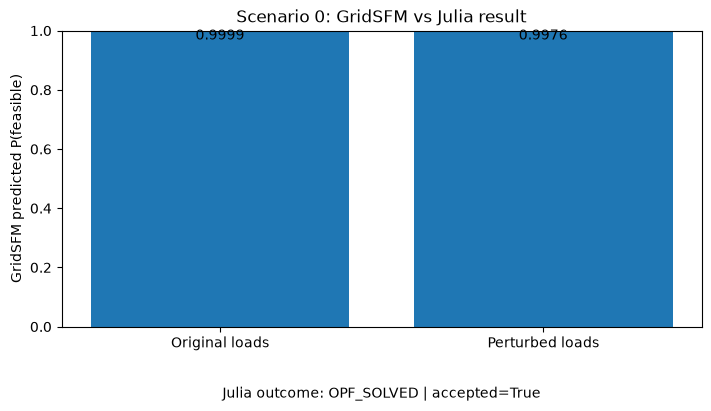

In [14]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
values = [p_original, p_selected]
ax.bar(["Original loads", "Perturbed loads"], values)
ax.set_ylim(0, 1)
ax.set_ylabel("GridSFM predicted P(feasible)")
ax.set_title(f"Scenario {SCENARIO_INDEX}: GridSFM vs Julia result")
for x, val in enumerate(values):
    ax.text(x, min(float(val) + .03, .97), f"{val:.4f}", ha="center")
ax.text(.5, -.24, f"Julia outcome: {saved_status[SCENARIO_INDEX]} | accepted={bool(julia_accepted[SCENARIO_INDEX])}",
        ha="center", transform=ax.transAxes, fontsize=10)
fig.savefig(EXPLAIN_DIR / "02_feasibility_before_after.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "02_feasibility_before_after.svg", bbox_inches="tight")
plt.show()

## 5 Captum Kernel SHAP: Pd vs Qd by geographical load group

Explaining 988 individual load entries with Kernel SHAP directly would be expensive. Instead, split Alabama loads into **12 longitude bands**, giving 24 interpretable features: `band 1 Pd`, `band 1 Qd`, ... `band 12 Qd`. For each masked feature, Captum restores that *group's channel* to the unperturbed value. All other attributes stay as sampled. This is a SHAP-style local approximation about **this one network scenario**.

**Caveat:** All intermediate perturbation combinations are hypothetical load scenarios. They are not individually validated by Julia. `N_SHAP_SAMPLES` controls evaluation cost; start with 64 and increase to 256+ once the pipeline works.

In [15]:
N_BANDS = 12
N_SHAP_SAMPLES = 64  # 64 model evaluations may take several minutes on CPU.

# Quantile-based longitude bands; sorted by west-east position.
lon_edges = np.quantile(longitudes, np.linspace(0, 1, N_BANDS+1))
# Searchsorted on interior edges avoids the rightmost-edge overflow.
band_idx = np.searchsorted(lon_edges[1:-1], longitudes, side="right").astype(int)
assert band_idx.min() >= 0 and band_idx.max() < N_BANDS

# Each band/channel pair is one Captum feature.
feature_mask = np.zeros((1, n_loads, 2), dtype=np.int64)
feature_mask[0, :, 0] = 2*band_idx
feature_mask[0, :, 1] = 2*band_idx + 1
feature_mask_t = torch.from_numpy(feature_mask)

x_input = torch.tensor(chosen[None, ...], dtype=torch.float32)
x_base = torch.tensor(original[None, ...], dtype=torch.float32)

kernel_shap = KernelShap(feasibility_fn)
shap_t = kernel_shap.attribute(
    x_input, baselines=x_base, feature_mask=feature_mask_t,
    n_samples=N_SHAP_SAMPLES, perturbations_per_eval=1,
    show_progress=True,
)
shap_grid = shap_t.squeeze(0).detach().cpu().numpy()
shap_band = np.array([
    [float(shap_grid[band_idx == g, j].mean()) for j in range(2)]
    for g in range(N_BANDS)
])
# Captum broadcasts a group attribution to every member of that group.
# DO NOT sum repeated per-load values, because that would overcount group SHAP.
assert np.isfinite(shap_band).all(), "Nonfinite SHAP. Investigate model numerical behavior."
print("Group SHAP result shape:", shap_band.shape)
print("Positive: increases predicted feasibility relative to original Alabama loads")
print("Negative: decreases predicted feasibility relative to original Alabama loads")

Kernel Shap attribution: 100%|██████████| 64/64 [00:20<00:00,  3.18it/s]


Group SHAP result shape: (12, 2)
Positive: increases predicted feasibility relative to original Alabama loads
Negative: decreases predicted feasibility relative to original Alabama loads


## 6 Visualize group-level Pd and Qd SHAP

The plot answers *which geographical part of Alabama and which power component (Pd or Qd) drove the model's prediction difference?* A negative bar indicates a decrease in model-predicted feasibility, **not** a proof of physical infeasibility.

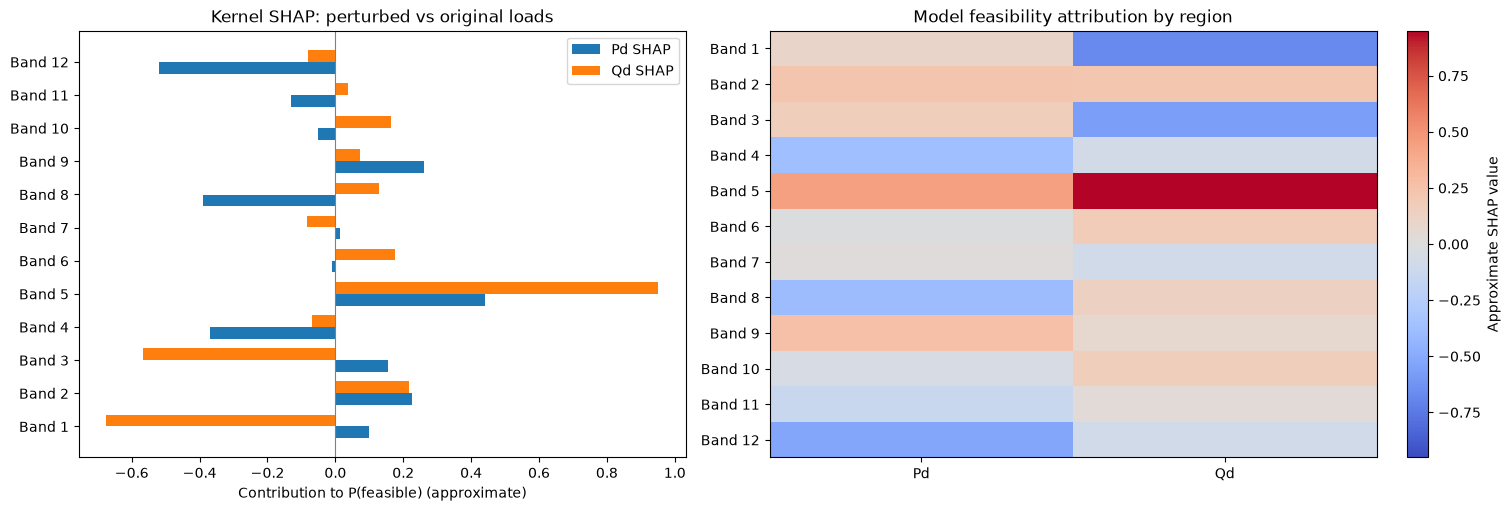

Top groups by |SHAP|:
{'band': 5, 'n_loads': 41, 'longitude_min': -87.0585318, 'longitude_max': -86.86031919999999, 'pd_shap': 0.4416715204715729, 'qd_shap': 0.9510990977287292, 'total_delta_pd_pu': 0.7322899103164673, 'total_delta_qd_pu': 0.31189537048339844}
{'band': 1, 'n_loads': 42, 'longitude_min': -88.3359055, 'longitude_max': -88.0215213, 'pd_shap': 0.09993048012256622, 'qd_shap': -0.6747838854789734, 'total_delta_pd_pu': 1.0076870918273926, 'total_delta_qd_pu': 0.4293339252471924}
{'band': 3, 'n_loads': 41, 'longitude_min': -87.76425557499999, 'longitude_max': -87.48413790000001, 'pd_shap': 0.15624099969863892, 'qd_shap': -0.5668113231658936, 'total_delta_pd_pu': 0.11504311859607697, 'total_delta_qd_pu': 0.04890640825033188}
{'band': 12, 'n_loads': 42, 'longitude_min': -85.39151035, 'longitude_max': -85.01737875, 'pd_shap': -0.5209128856658936, 'qd_shap': -0.08145059645175934, 'total_delta_pd_pu': 0.9304952621459961, 'total_delta_qd_pu': 0.3964126408100128}
{'band': 8, 'n_loads

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ys = np.arange(N_BANDS)
ax1.barh(ys-0.18, shap_band[:, 0], height=0.35, label="Pd SHAP")
ax1.barh(ys+0.18, shap_band[:, 1], height=0.35, label="Qd SHAP")
ax1.axvline(0, color="gray", linewidth=0.8)
ax1.set_yticks(ys, [f"Band {i+1}" for i in ys])
ax1.set_xlabel("Contribution to P(feasible) (approximate)")
ax1.set_title("Kernel SHAP: perturbed vs original loads")
ax1.legend()

vmax = max(float(np.abs(shap_band).max()), 1e-8)
im = ax2.imshow(shap_band, cmap="coolwarm", aspect="auto", vmin=-vmax, vmax=vmax)
ax2.set_xticks([0, 1], ["Pd", "Qd"])
ax2.set_yticks(ys, [f"Band {i+1}" for i in ys])
ax2.set_title("Model feasibility attribution by region")
fig.colorbar(im, ax=ax2, label="Approximate SHAP value")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.svg", bbox_inches="tight")
plt.show()

band_table = []
for i in range(N_BANDS):
    members = band_idx == i
    band_table.append({
        "band": i+1, "n_loads": int(members.sum()),
        "longitude_min": float(longitudes[members].min()),
        "longitude_max": float(longitudes[members].max()),
        "pd_shap": float(shap_band[i,0]), "qd_shap": float(shap_band[i,1]),
        "total_delta_pd_pu": float(delta[members,0].sum()),
        "total_delta_qd_pu": float(delta[members,1].sum()),
    })
print("Top groups by |SHAP|:")
for entry in sorted(band_table, key=lambda row: max(abs(row["pd_shap"]),abs(row["qd_shap"])), reverse=True)[:8]:
    print(entry)

## Visual C — Ranked SHAP contributions (local explanation)

Each bar represents one **group/channel** (longitude band × Pd or Qd). Positive SHAP values increase the model's predicted feasibility relative to the original Alabama loads; negative values decrease it. Group values are **not** per-load SHAP scores. The attribution sum is an approximation and may differ from the measured model-probability change.

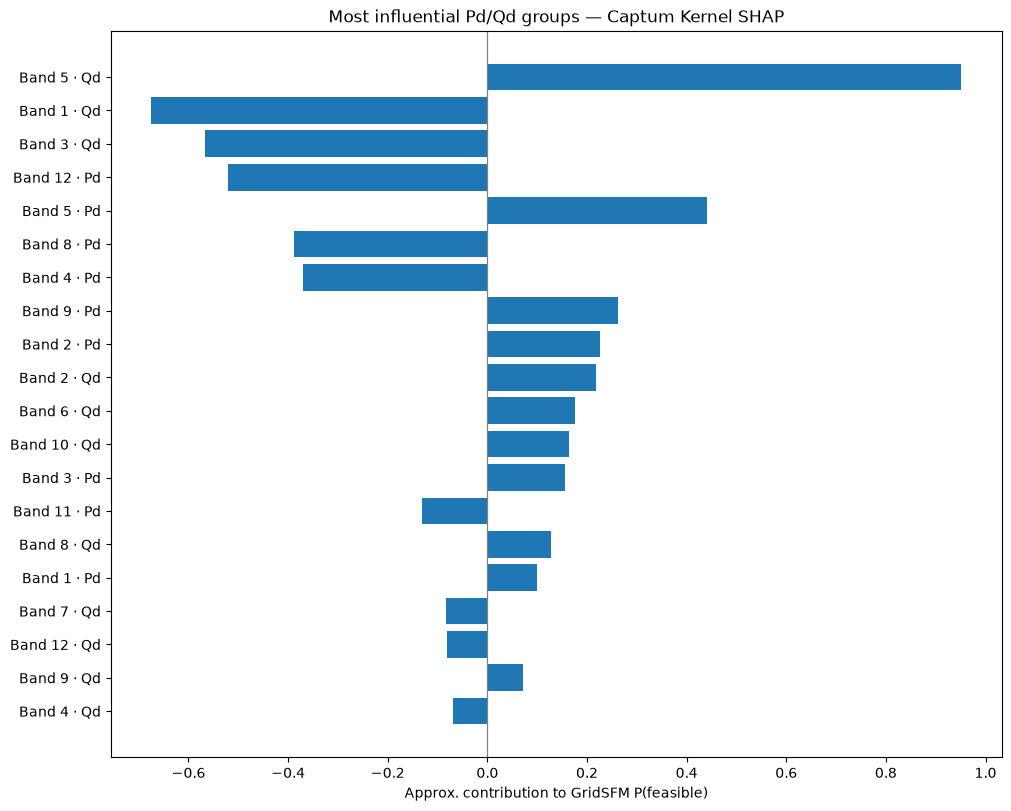

Model P(feasible) difference: -0.002366
Sum of group SHAP contributions (approx.): -0.00236
Gap (attribution estimate − model difference): 6e-06
Total absolute group attribution: Pd= 2.671877 Qd= 3.222398


In [17]:
labels = [f"Band {g+1} · {channel}" for g in range(N_BANDS) for channel in ("Pd", "Qd")]
values = shap_band.reshape(-1)
ranked = np.argsort(np.abs(values))[::-1][:min(20, len(values))]
ranked = ranked[::-1]  # largest magnitudes at the top
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
ax.barh([labels[k] for k in ranked], values[ranked])
ax.axvline(0, lw=.9, color="gray")
ax.set_xlabel("Approx. contribution to GridSFM P(feasible)")
ax.set_title("Most influential Pd/Qd groups — Captum Kernel SHAP")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.svg", bbox_inches="tight")
plt.show()

print("Model P(feasible) difference:", round(p_selected-p_original, 6))
print("Sum of group SHAP contributions (approx.):", round(float(values.sum()), 6))
print("Gap (attribution estimate − model difference):", round(float(values.sum()-(p_selected-p_original)), 6))
print("Total absolute group attribution: Pd=", round(float(np.abs(shap_band[:,0]).sum()),6),
      "Qd=", round(float(np.abs(shap_band[:,1]).sum()),6))

## 7 Which **individual loads** should we investigate?

Kernel SHAP above explains 24 *groups*. The following inexpensive follow-up uses **Captum `FeatureAblation`**, not SHAP, to estimate individual-load effects for the 12 loads with the largest absolute changes in the **most influential group**. It replaces one selected load's Pd or Qd with its original value while keeping all other perturbations. The reported difference is local and conditional, so do not call it a true per-load SHAP value.

Increase `TOP_K_LOADS` for a broader follow-up. For exact all-load attribution, use many more model evaluations and repeated independent explanations.

In [18]:
TOP_K_LOADS = 12
strongest_feature = int(np.abs(shap_band).argmax())
strongest_band, strongest_channel = np.unravel_index(strongest_feature, shap_band.shape)
within = np.flatnonzero(band_idx == strongest_band)
score = np.abs(delta[within, strongest_channel])
selected_pyg_rows = within[np.argsort(score)[-min(TOP_K_LOADS, len(within)):][::-1]]
print("Selected influential band:", strongest_band + 1,
      "channel:", ["Pd", "Qd"][strongest_channel])
print("Inspecting", len(selected_pyg_rows), "individual loads")

# Only explain these 12 load/channel entries. Other inputs remain constant;
# assigning a common mask ID to other loads would ablate them as a huge group,
# so instead use a focused parameterization on a vector of K changes.
feature_pairs = [(int(r), int(j)) for r in selected_pyg_rows for j in (0, 1)]

def focused_forward(z):
    # Each row z contains the chosen load/channel values; other loads remain
    # at the chosen sampled values. Baseline for these features = original values.
    outputs = []
    for z_row in z.detach().cpu().numpy():
        test = chosen.copy()
        for k, (r, j) in enumerate(feature_pairs):
            test[r, j] = float(z_row[k])
        outputs.append(grid_probability_pygrid(test))
    return torch.tensor(outputs, dtype=torch.float32, device=z.device)

focus_x = torch.tensor([[chosen[r,j] for r,j in feature_pairs]], dtype=torch.float32)
focus_base = torch.tensor([[original[r,j] for r,j in feature_pairs]], dtype=torch.float32)
focus_attr = FeatureAblation(focused_forward).attribute(
    focus_x, baselines=focus_base, perturbations_per_eval=1,
    show_progress=True,
).squeeze(0).numpy()

individual_table = []
for k, ((r,j), impact) in enumerate(zip(feature_pairs, focus_attr)):
    individual_table.append({
        "pyg_row": int(r), "load_id": pyg_load_ids[r],
        "bus_id": pyg_load_bus_id[r], "bus_name": data["bus"][pyg_load_bus_id[r]].get("name", ""),
        "channel": ["Pd", "Qd"][j],
        "original_pu": float(original[r,j]),
        "perturbed_pu": float(chosen[r,j]),
        "change_pu": float(delta[r,j]),
        "ablation_effect": float(impact),
    })
individual_table.sort(key=lambda r: abs(r["ablation_effect"]), reverse=True)
print("Top individual load effects (FeatureAblation, NOT per-load SHAP):")
for row in individual_table[:15]:
    print(row)

Selected influential band: 5 channel: Qd
Inspecting 12 individual loads


Feature Ablation attribution: 100%|██████████| 25/25 [00:07<00:00,  3.23it/s]

Top individual load effects (FeatureAblation, NOT per-load SHAP):
{'pyg_row': 218, 'load_id': '219', 'bus_id': '229', 'bus_name': 'Aldrich Substation', 'channel': 'Qd', 'original_pu': 0.09089499711990356, 'perturbed_pu': 0.0360015407204628, 'change_pu': -0.054893456399440765, 'ablation_effect': 0.0012072920799255371}
{'pyg_row': 86, 'load_id': '87', 'bus_id': '37', 'bus_name': 'Evergreen Substation', 'channel': 'Qd', 'original_pu': 0.09229841828346252, 'perturbed_pu': 0.03363632410764694, 'change_pu': -0.05866209417581558, 'ablation_effect': 0.0010187029838562012}
{'pyg_row': 405, 'load_id': '406', 'bus_id': '550', 'bus_name': 'United States Steel Corp Substation', 'channel': 'Pd', 'original_pu': 0.028991008177399635, 'perturbed_pu': 0.13596558570861816, 'change_pu': 0.10697457939386368, 'ablation_effect': 0.0009756088256835938}
{'pyg_row': 403, 'load_id': '404', 'bus_id': '548', 'bus_name': 'United States Steel Corp Substation', 'channel': 'Pd', 'original_pu': 0.08082342147827148, 'pe

## Visual D — Individual load changes that matter to GridSFM

This plot uses **Feature Ablation**, not Kernel SHAP. It takes the most perturbed loads within the strongest SHAP group, and compares the pretrained model's output with one Pd/Qd value reverted to its original value. Values reflect the model's dependence on that change **in the context of all other perturbations**.

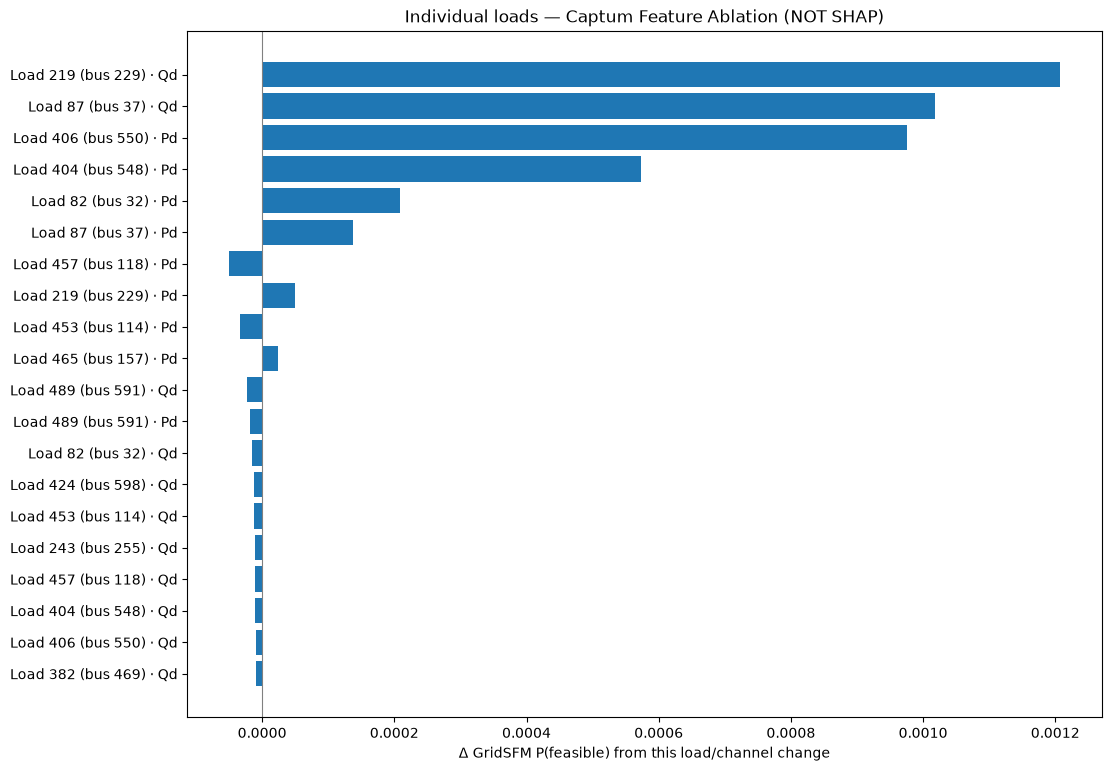

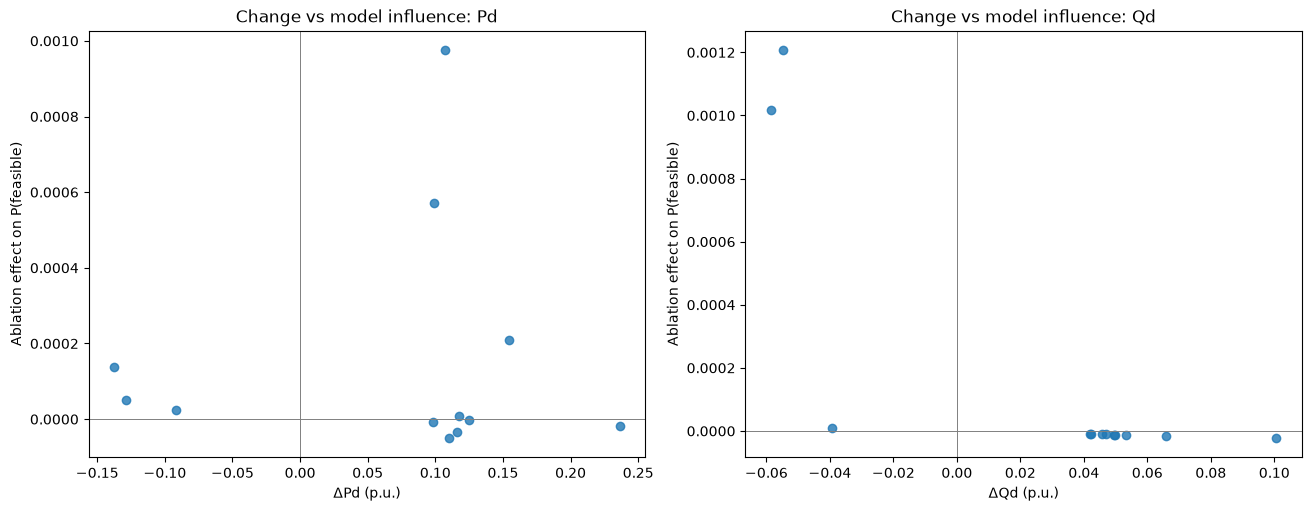

In [19]:
# Ranked individual-load ablation effects.
show = individual_table[:min(20, len(individual_table))]
fig, ax = plt.subplots(figsize=(11, max(5, len(show)*.38)), constrained_layout=True)
ax.barh([f"Load {r['load_id']} (bus {r['bus_id']}) · {r['channel']}" for r in show[::-1]],
        [r["ablation_effect"] for r in show[::-1]])
ax.axvline(0, color="gray", linewidth=.8)
ax.set_xlabel("Δ GridSFM P(feasible) from this load/channel change")
ax.set_title("Individual loads — Captum Feature Ablation (NOT SHAP)")
fig.savefig(EXPLAIN_DIR / "04_ranked_individual_load_ablation.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "04_ranked_individual_load_ablation.svg", bbox_inches="tight")
plt.show()

# Compare actual changes with model attribution for investigated loads.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    sub = [r for r in individual_table if r["channel"] == name]
    axs[j].scatter([r["change_pu"] for r in sub],
                   [r["ablation_effect"] for r in sub], alpha=.8)
    axs[j].axhline(0, color="gray", linewidth=.7)
    axs[j].axvline(0, color="gray", linewidth=.7)
    axs[j].set(xlabel=f"Δ{name} (p.u.)", ylabel="Ablation effect on P(feasible)",
               title=f"Change vs model influence: {name}")
fig.savefig(EXPLAIN_DIR / "05_load_change_vs_ablation_effect.png", dpi=180, bbox_inches="tight")
plt.show()

## 8 Export the results for your research report

Use the tables to report: (1) model probability before/after perturbation, (2) Julia outcome, (3) largest absolute Pd/Qd group attributions, (4) top investigated loads and their buses. **Do not** claim that a model attribution proves a bus caused the solver to fail.

In [20]:
import csv
EXPLAIN_DIR = OUTPUT_DIR / "pretrained_gridsfm_captum"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader(); w.writerows(rows)

write_csv(EXPLAIN_DIR / "alabama_pd_qd_group_kernelshap.csv", band_table)
write_csv(EXPLAIN_DIR / "alabama_pd_qd_load_feature_ablation.csv", individual_table)
summary = {
    "checkpoint": str(CHECKPOINT_PATH),
    "pyg_case": str(PYG_PATH),
    "source_case": str(DATA_PATH.resolve()),
    "selected_scenario_index": int(SCENARIO_INDEX),
    "iteration": int(saved_iteration[SCENARIO_INDEX]),
    "scenario": int(saved_scenario[SCENARIO_INDEX]),
    "julia_accepted": bool(julia_accepted[SCENARIO_INDEX]),
    "julia_status": str(saved_status[SCENARIO_INDEX]),
    "gridsfm_original_p_feasible": float(p_original),
    "gridsfm_perturbed_p_feasible": float(p_selected),
    "gridsfm_delta_p_feasible": float(p_selected - p_original),
    "n_bands": int(N_BANDS),
    "kernelshap_samples": int(N_SHAP_SAMPLES),
    "method_group": "Captum KernelShap with longitudinal Pd/Qd feature grouping",
    "method_individual": "Captum FeatureAblation on selected load/channels (not SHAP)",
    "interpretation_warning": "Attributions explain GridSFM, not guaranteed AC-OPF causal failure; Alabama 494 buses is below pretrained model's 500-bus support guidance.",
}
with (EXPLAIN_DIR / "run_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Saved explanation files under:", EXPLAIN_DIR.resolve())

Saved explanation files under: /Users/punrong_rany/Desktop/Projects/GridSFM/model/samples/gaussian_load_centered/pretrained_gridsfm_captum


## 9 Reading your explanations

- If **Pd SHAP is negative in band 7**, the perturbations to active loads in that band collectively **reduced the pretrained GridSFM model's feasibility probability** relative to the original Alabama loads.
- If **Qd SHAP is positive in band 2**, the perturbations to reactive loads in that band collectively **increased that prediction**.
- For an individual load, the `ablation_effect` reflects the predicted-probability change from that load/channel difference *while other loads stay perturbed*. It is **not** a per-load SHAP value.
- Since the model is **pretrained**, you do not need `alabama_surrogate_weights.pt`, `alabama_surrogate_scaler.npz`, or both classes of Julia labels. Keep the Julia solver outcomes to **compare** against GridSFM.
- This is a **local, counterfactual-style interpretation of model predictions**. It is not automatically a physical proof that a bus causes AC-OPF infeasibility. For causal/physical claims, perturb or restore identified loads and **rerun Julia AC-OPF** to test the hypothesis.
- Alabama has **494 buses**, slightly under the released checkpoint's documented training regime (500+). Consider a 500+ bus grid for stronger scientific evaluation, and compare several sampling seeds and SHAP repeats.